# AI Project 2: Visual Product Recommendations

A customer uploads a photo of clothing and gets the 5 most visually similar products from the retailer's catalogue, each with its cosine similarity score. Images are turned into embeddings with a pre-trained ResNet50 and compared with cosine similarity.

## 1. Data Processing and Cleaning

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import kagglehub
path = kagglehub.dataset_download("kaborg15/vibrent-clothes-rental-dataset")
print(path)

import os
print(os.listdir(path))

Resuming download from 564133888 bytes (6057407387 bytes left)...
Resuming download to /root/.cache/kagglehub/datasets/kaborg15/vibrent-clothes-rental-dataset/7.archive (564133888/6621541275) bytes left.


100%|██████████| 6.17G/6.17G [01:12<00:00, 83.3MB/s]

Extracting files...


/root/.cache/kagglehub/datasets/kaborg15/vibrent-clothes-rental-dataset/versions/7
['additional_tabular_data', 'user_activity_triplets.csv', 'embeddings', 'picture_triplets.csv', 'images', 'outfits.csv']


In [ ]:
import shutil
dest = "/content/drive/MyDrive/project2/data"
shutil.copytree(path, dest, dirs_exist_ok=True)
print("Copied to Drive")

Copied to Drive


In [ ]:
import os

# Show the folder structure (top 3 levels) and how many files are in each folder
for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)
    if depth <= 2:
        indent = "    " * depth
        folder_name = os.path.basename(root) or "root"
        print(f"{indent}{folder_name}/   ({len(files)} files)")

# Count all the image files
exts = ('.jpg', '.jpeg', '.png', '.webp')
images = [os.path.join(r, f) for r, _, fs in os.walk(path) for f in fs if f.lower().endswith(exts)]
print("\nTotal images found:", len(images))

7/   (3 files)
    additional_tabular_data/   (4 files)
    embeddings/   (0 files)
        EfficientNet_V2_L_final/   (50293 files)
    images/   (50293 files)

Total images found: 50293


Only 33,565 of the 50,293 images made it into the Drive copy, so cleaning runs on those 33,565.

In [ ]:
import os
raw_images_path = '/content/drive/MyDrive/project2/data/images'
raw_count = len(os.listdir(raw_images_path))
print(f"Images in data/images/: {raw_count}")

Images in data/images/: 33565


In [ ]:
import hashlib
from PIL import Image
import os
import pandas as pd

raw_path = '/content/drive/MyDrive/project2/data/images'
output_cleaned_path = '/content/drive/MyDrive/project2/cleaned_images_v2'
os.makedirs(output_cleaned_path, exist_ok=True)

invalid_images = []
duplicate_hashes = {}
cleaned_files = []

raw_files = os.listdir(raw_path)
print(f"Starting with {len(raw_files)} images")

for idx, filename in enumerate(raw_files):
    if idx % 5000 == 0:
        print(f"Processing: {idx}/{len(raw_files)}")

    filepath = os.path.join(raw_path, filename)

    try:
        img = Image.open(filepath).convert('RGB')

        if img.size[0] < 50 or img.size[1] < 50:
            invalid_images.append(filename)
            continue

        with open(filepath, 'rb') as f:
            file_hash = hashlib.md5(f.read()).hexdigest()

        if file_hash in duplicate_hashes:
            invalid_images.append(filename)
            continue

        duplicate_hashes[file_hash] = filename

        output_path = os.path.join(output_cleaned_path, filename)
        img.save(output_path, 'JPEG', quality=95)
        cleaned_files.append(filename)

    except Exception as e:
        invalid_images.append(filename)

print(f"\nCleaning complete:")
print(f"Cleaned: {len(cleaned_files)}")
print(f"Invalid: {len(invalid_images)}")
print(f"Removed: {len(raw_files) - len(cleaned_files)}")

df_cleaned = pd.DataFrame({'filename': cleaned_files})
df_cleaned.to_csv('/content/drive/MyDrive/project2/cleaned_images_v2.csv', index=False)
print(f"\nSaved {len(cleaned_files)} cleaned images")
print(f"CSV saved: cleaned_images_v2.csv")

Starting with 33565 images
Processing: 0/33565
Processing: 5000/33565
Processing: 10000/33565
Processing: 15000/33565
Processing: 20000/33565
Processing: 25000/33565
Processing: 30000/33565

Cleaning complete:
  Cleaned: 23023
  Invalid: 10542
  Removed: 10542

Saved 23023 cleaned images
CSV saved: cleaned_images_v2.csv


In [ ]:
import os
import hashlib
from PIL import Image
from concurrent.futures import ThreadPoolExecutor

# Counts why each image was removed, using the same rules as the cleaning cell above
# It only reads the files, nothing is saved or deleted
raw_path = '/content/drive/MyDrive/project2/data/images'
raw_files = os.listdir(raw_path)

def check_reason(filename):
    filepath = os.path.join(raw_path, filename)
    try:
        img = Image.open(filepath).convert('RGB')
        if img.size[0] < 50 or img.size[1] < 50:
            return 'too small', None
        with open(filepath, 'rb') as f:
            return 'ok', hashlib.md5(f.read()).hexdigest()
    except Exception:
        return 'unreadable', None

with ThreadPoolExecutor(max_workers=16) as executor:
    checks = list(executor.map(check_reason, raw_files))

# The first copy of each image is kept and every later copy counts as a duplicate
seen_hashes = set()
counts = {'kept': 0, 'unreadable': 0, 'too small': 0, 'duplicate': 0}
for status, file_hash in checks:
    if status != 'ok':
        counts[status] += 1
    elif file_hash in seen_hashes:
        counts['duplicate'] += 1
    else:
        seen_hashes.add(file_hash)
        counts['kept'] += 1

print(f"Raw images: {len(raw_files)}")
for reason, n in counts.items():
    print(f"{reason}: {n}")
print(f"Total removed: {len(raw_files) - counts['kept']}")

## 2. Feature Creation

In [ ]:
import torch
import torchvision.transforms as transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import pandas as pd

In [ ]:
# Define Image Transformation Pipeline
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])
print("Image transformation pipeline has been created")

In [ ]:
def test_transformation_on_single_image(image_path):
    # Test the transformation pipeline on one image to verify it works.
    try:
        original_img = Image.open(image_path).convert('RGB')
        original_size = original_img.size
        transformed_tensor = image_transform(original_img)

        print(f"Image loaded successfully")
        print(f"Original size: {original_size}")
        print(f"Transformed shape: {transformed_tensor.shape}")
        print(f"Tensor value range: [{transformed_tensor.min():.4f}, {transformed_tensor.max():.4f}]")

        return transformed_tensor, original_img

    except Exception as e:
        print(f"Error processing image: {e}")
        return None, None

In [ ]:
df_cleaned = pd.read_csv('/content/drive/MyDrive/project2/cleaned_images_v2.csv')
test_image_path = f'/content/drive/MyDrive/project2/cleaned_images_v2/{df_cleaned["filename"].iloc[0]}'

transformed, original = test_transformation_on_single_image(test_image_path)

In [ ]:
def visualize_transformation(original_img, transformed_tensor):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].imshow(original_img)
    axes[0].set_title('Original Image')
    axes[0].axis('off')

    denorm_transform = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )

    denorm_img = denorm_transform(transformed_tensor)
    denorm_img = torch.clamp(denorm_img, 0, 1)
    denorm_img_pil = transforms.ToPILImage()(denorm_img)

    axes[1].imshow(denorm_img_pil)
    axes[1].set_title('After Transformation (224×224)')
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

In [ ]:
visualize_transformation(original, transformed)

In [ ]:
df_cleaned_v2 = pd.read_csv('/content/drive/MyDrive/project2/cleaned_images_v2.csv')

def batch_transform_all_images_v2(csv_path, image_dir):
    df = pd.read_csv(csv_path)
    image_paths = [f"{image_dir}/{fname}" for fname in df['filename']]

    transformed_list = []
    failed_images = []

    for idx, img_path in enumerate(image_paths):
        if idx % 5000 == 0:
            print(f"Processing: {idx}/{len(image_paths)}")

        try:
            img = Image.open(img_path).convert('RGB')
            transformed = image_transform(img)
            transformed_list.append(transformed)
        except Exception as e:
            failed_images.append((img_path, str(e)))

    batch_tensor = torch.stack(transformed_list)
    print(f"Success: {len(transformed_list)} images")
    print(f"Batch shape: {batch_tensor.shape}")
    return batch_tensor, failed_images

batch_tensor_v2, failed_v2 = batch_transform_all_images_v2(
    '/content/drive/MyDrive/project2/cleaned_images_v2.csv',
    '/content/drive/MyDrive/project2/cleaned_images_v2'
)

In [ ]:
torch.save(batch_tensor_v2, '/content/drive/MyDrive/project2/transformed_batch_v2.pt')
print("Batch tensor saved")

Batch tensor saved


## 3. Image Recommendation Model

Pre-trained ResNet50 (ImageNet V1 weights) with the final classification layer removed, so each image becomes a 2,048-number embedding.

In [ ]:
from torchvision import models
from torch import nn

model = models.resnet50(pretrained=True)
model = nn.Sequential(*list(model.children())[:-1])
model.eval()

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = model.to(device)

print(f"Model loaded on {device}")
print("Generating embeddings for all 23,023 images...")

embeddings_list = []

with torch.no_grad():
    for idx in range(0, len(batch_tensor_v2), 32):
        batch = batch_tensor_v2[idx:idx+32].to(device)
        embedding = model(batch)
        embedding = embedding.squeeze(-1).squeeze(-1)
        embeddings_list.append(embedding.cpu())

        if idx % 2000 == 0:
            print(f"Processed: {idx}/{len(batch_tensor_v2)}")

embeddings = torch.cat(embeddings_list, dim=0)
print(f"Embeddings shape: {embeddings.shape}")
print(f"Each image has {embeddings.shape[1]} dimensional embedding")

torch.save(embeddings, '/content/drive/MyDrive/project2/embeddings_v2.pt')
print("Embeddings saved")

## 4. Output Functions

The first cell reloads everything saved above, so this section can be run in a new session without repeating sections 1 to 3.

In [ ]:
# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import all required libraries
import torch
import torchvision.transforms as transforms
from torchvision import models
from torch import nn
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

# Define image transformation pipeline (identical to Stage 3)
image_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Load saved data from Google Drive
embeddings = torch.load('/content/drive/MyDrive/project2/embeddings_v2.pt')
df_cleaned_v2 = pd.read_csv('/content/drive/MyDrive/project2/cleaned_images_v2.csv')
image_dir = '/content/drive/MyDrive/project2/cleaned_images_v2'

# Set device (GPU if available, CPU otherwise)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Load ResNet50 model (identical to Stage 4)
model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
model = nn.Sequential(*list(model.children())[:-1])
model = model.to(device)
model.eval()

# Verify everything loaded correctly
print("Checkpoint loading complete!")
print(f"Embeddings shape: {embeddings.shape}")
print(f"Number of cleaned images: {len(df_cleaned_v2)}")
print(f"Image directory: {image_dir}")
print(f"Device: {device}")
print(f"Model loaded: ResNet50")

Mounted at /content/drive
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 159MB/s]


Checkpoint loading complete!
Embeddings shape: torch.Size([23023, 2048])
Number of cleaned images: 23023
Image directory: /content/drive/MyDrive/project2/cleaned_images_v2
Device: cpu
Model loaded: ResNet50


In [ ]:
import torch.nn.functional as F

# Turn any image into a 2048-number embedding
def get_embedding(image):
    if isinstance(image, str):
        image = Image.open(image)
    image = image.convert('RGB')
    tensor = image_transform(image).unsqueeze(0).to(device)
    with torch.no_grad():
        embedding = model(tensor).flatten(1)
    return embedding.cpu()

# Measures Cosine similarity
def cosine_similarity_score(embedding_a, embedding_b):
    return F.cosine_similarity(embedding_a, embedding_b)

# Output function 1: two images and get back one similarity score
def compare_two_images(image_a, image_b):
    return cosine_similarity_score(get_embedding(image_a), get_embedding(image_b)).item()

# Output function 2: score one image against all saved embeddings and keep the closest N
def find_similar_images(image, n=5):
    query = get_embedding(image)
    scores = cosine_similarity_score(query, embeddings)
    top_scores, top_indices = torch.topk(scores, n)
    filenames = df_cleaned_v2['filename'].iloc[top_indices.tolist()].tolist()
    return filenames, top_scores.tolist()

In [ ]:
# Show the input image next to its 5 closest matches, each labelled with its score
def show_recommendations(image_path, n=5):
    filenames, scores = find_similar_images(image_path, n)
    fig, axes = plt.subplots(1, n + 1, figsize=(3 * (n + 1), 4))

    axes[0].imshow(Image.open(image_path).convert('RGB'))
    axes[0].set_title('Input image')

    for ax, fname, score in zip(axes[1:], filenames, scores):
        ax.imshow(Image.open(f"{image_dir}/{fname}"))
        ax.set_title(f"Score: {score:.3f}")

    for ax in axes:
        ax.axis('off')

    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/project2/sample_output.png', bbox_inches='tight')
    plt.show()

## 5. Model Outputs

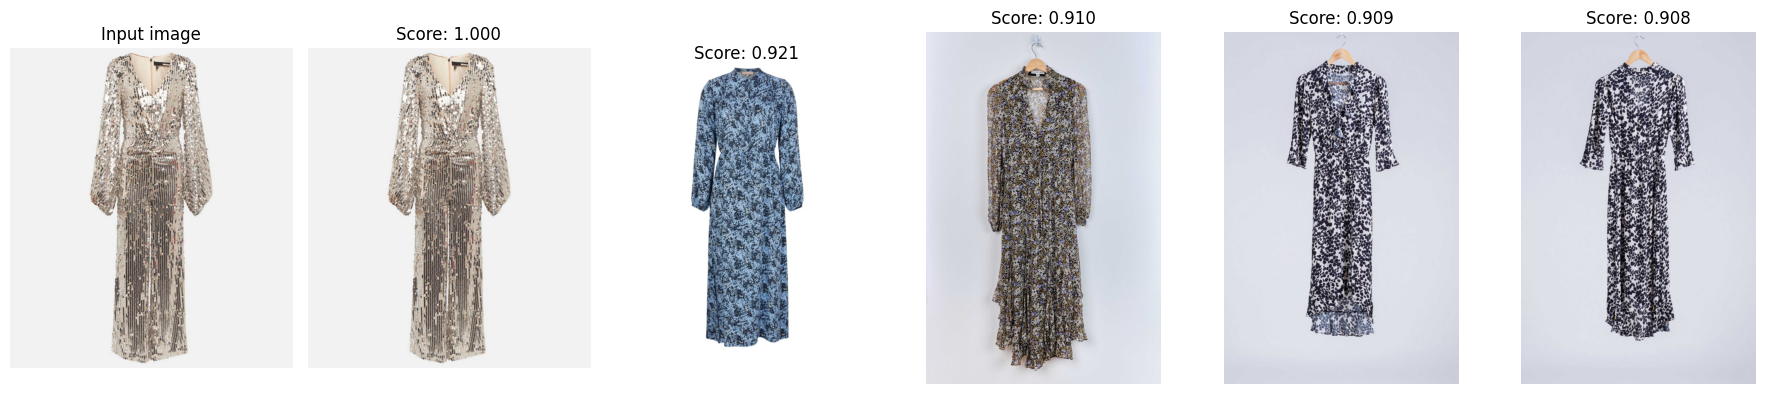

In [ ]:
sample_path = f"{image_dir}/{df_cleaned_v2['filename'].iloc[0]}"
show_recommendations(sample_path)

Saving 210307481-2.avif to 210307481-2.avif


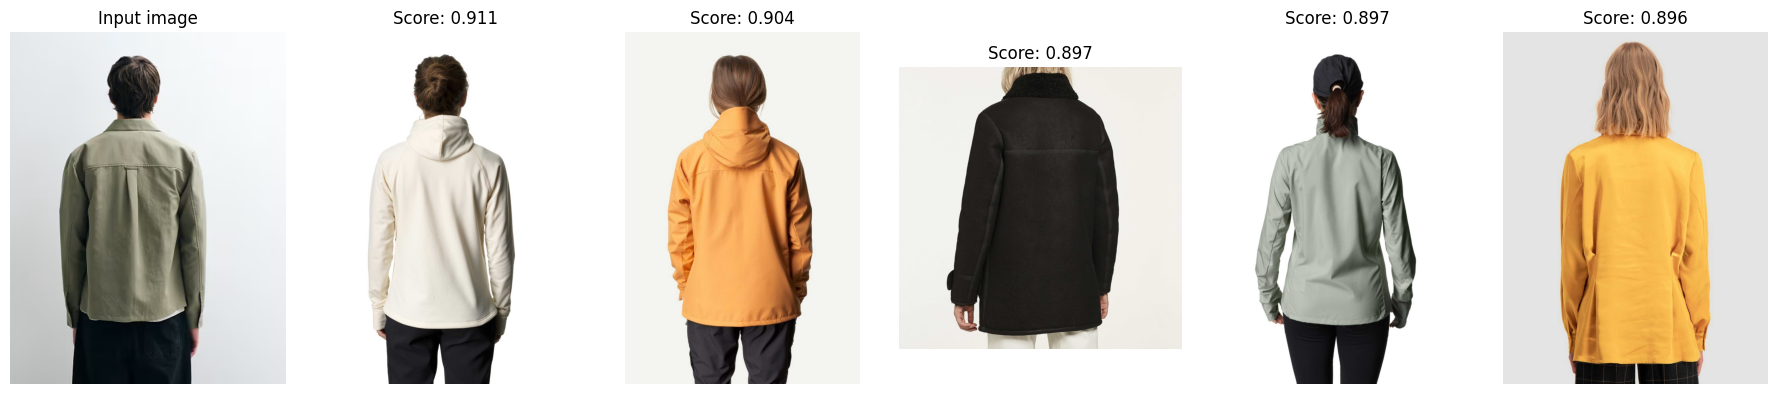

In [ ]:
from google.colab import files

# Pick a clothing photo from your computer
uploaded = files.upload()
test_image_path = list(uploaded.keys())[0]
show_recommendations(test_image_path)

## 6. Model Deployment

The live app's code is in `clothing-recommender/` (`streamlit_app.py` and `requirements.txt`) and is hosted on Streamlit Community Cloud. The cells below prepare and upload the files the app downloads from the Hugging Face dataset `abz2781/clothing-recommender-data`.

In [ ]:
import os

thumb_dir = '/content/drive/MyDrive/project2/deploy/thumbnails'
os.makedirs(thumb_dir, exist_ok=True)

# The website only needs small copies of each image to show as results
already_done = set(os.listdir(thumb_dir))

for fname in df_cleaned_v2['filename']:
    if fname in already_done:
        continue
    img = Image.open(f"{image_dir}/{fname}").convert('RGB')
    img.thumbnail((300, 300))
    img.save(f"{thumb_dir}/{fname}", 'JPEG', quality=85)

print(f"Thumbnails ready: {len(os.listdir(thumb_dir))}")

Thumbnails ready: 23023


In [ ]:
import shutil

deploy_dir = '/content/drive/MyDrive/project2/deploy'

# One zip file uploads far more reliably than 23,023 separate files
shutil.make_archive('/content/thumbnails', 'zip', thumb_dir)
shutil.copy('/content/thumbnails.zip', f"{deploy_dir}/thumbnails.zip")

# Put the embeddings and filename list alongside it so the app has everything in one folder
shutil.copy('/content/drive/MyDrive/project2/embeddings_v2.pt', f"{deploy_dir}/embeddings.pt")
shutil.copy('/content/drive/MyDrive/project2/cleaned_images_v2.csv', f"{deploy_dir}/filenames.csv")

print(os.listdir(deploy_dir))

['thumbnails', 'thumbnails.zip', 'embeddings.pt', 'filenames.csv']


In [ ]:
from huggingface_hub import login
login()

In [ ]:
import os
import shutil

upload_dir = "/content/drive/MyDrive/project2/deploy_streamlit/upload_files"
os.makedirs(upload_dir, exist_ok=True)

shutil.copy("/content/drive/MyDrive/project2/embeddings_v2.pt", f"{upload_dir}/embeddings.pt")
shutil.copy("/content/drive/MyDrive/project2/cleaned_images_v2.csv", f"{upload_dir}/filenames.csv")
shutil.copy("/content/drive/MyDrive/project2/deploy/thumbnails.zip", f"{upload_dir}/thumbnails.zip")

print("Files copied to upload folder:")
print(os.listdir(upload_dir))

Files copied to upload folder:
['embeddings.pt', 'filenames.csv', 'thumbnails.zip']


In [ ]:
from huggingface_hub import upload_folder

upload_folder(
    folder_path="/content/drive/MyDrive/project2/deploy_streamlit/upload_files",
    repo_id="abz2781/clothing-recommender-data",
    repo_type="dataset",
    allow_patterns=["*.pt", "*.csv", "*.zip"]
)

CommitInfo(commit_url='https://huggingface.co/datasets/abz2781/clothing-recommender-data/commit/29e0d4291be63f39d0e6ee2e6d143d57c56df83d', commit_message='Upload folder using huggingface_hub', commit_description='', oid='29e0d4291be63f39d0e6ee2e6d143d57c56df83d', pr_url=None, repo_url=RepoUrl('https://huggingface.co/datasets/abz2781/clothing-recommender-data', endpoint='https://huggingface.co', repo_type='dataset', repo_id='abz2781/clothing-recommender-data'), pr_revision=None, pr_num=None)